# Heart Disease Prediction - Model Training
B.Tech CSE minor project. This notebook loads `dataset/heart.csv`, explores it, compares four models with
cross-validation, evaluates the best one on a held-out test set, and saves
`models/heart_disease_model.pkl` and `models/scaler.pkl` for the Flask app.

Run all cells from top to bottom. Run it with the **same scikit-learn version** you use to run `app.py`.

In [1]:
import json
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
# Your heart.csv has target 1 = NO disease (checked with the groupby below). The app expects
# 1 = disease, so labels are flipped. Set to False if your file already has 1 = disease.
FLIP_TARGET = True
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "dataset" / "heart.csv"
MODEL_DIR = ROOT / "models"
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal"]   # must match app.py

## 1. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
if FLIP_TARGET:
    df["target"] = 1 - df["target"]          # make 1 = heart disease, 0 = healthy
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
missing_cols = set(FEATURES + ["target"]) - set(df.columns)
assert not missing_cols, f"Columns missing from dataset: {missing_cols}"

# Label check: target = 1 (disease) should have LOWER thalach and HIGHER oldpeak, exang, ca
print(df.groupby("target")[["thalach", "oldpeak", "exang", "ca"]].mean().round(2))
df.head()

Shape: (302, 14)
Missing values: 0
Duplicate rows: 0
        thalach  oldpeak  exang    ca
target                               
0        158.38     0.59   0.14  0.34
1        139.10     1.59   0.55  1.17


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,1
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,1
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,1
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,1
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,1


## 2. Exploratory analysis

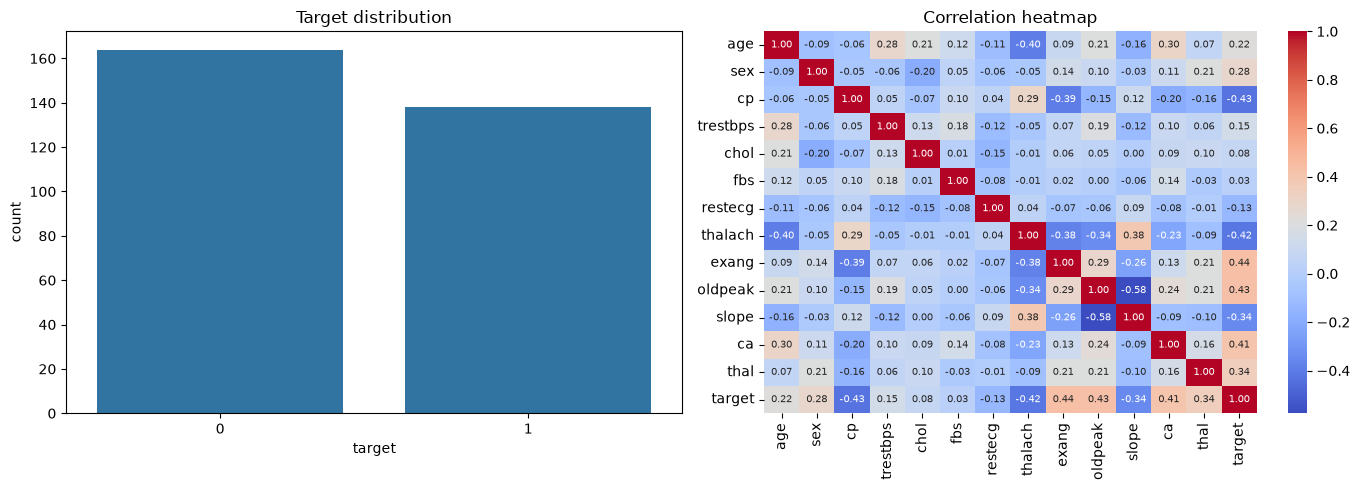

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x="target", data=df, ax=axes[0])
axes[0].set_title("Target distribution")
sns.heatmap(df[FEATURES + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Correlation heatmap")
plt.tight_layout(); plt.show()

## 3. Clean and split
Duplicate rows are dropped so the same patient cannot appear in both train and test sets.
A stratified split keeps the class balance equal in both sets.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
X, y = df[FEATURES], df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (241, 13)  Test: (61, 13)


## 4. Compare models
Each model sits in a pipeline with its own `StandardScaler`, so scaling is learned only from the
training part of each cross-validation fold (no data leakage). Hyper-parameters are tuned with
`GridSearchCV` using ROC-AUC.

In [5]:
candidates = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "SVM": (SVC(probability=True, random_state=RANDOM_STATE),
            {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1],
             "model__kernel": ["rbf", "linear"]}),
    "KNN": (KNeighborsClassifier(),
            {"model__n_neighbors": [3, 5, 7, 9, 11], "model__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
                      {"model__n_estimators": [100, 300], "model__max_depth": [None, 5, 10]}),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

searches, rows = {}, []
for name, (estimator, grid) in candidates.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", estimator)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    rows.append({"Model": name, "CV ROC-AUC": round(search.best_score_, 4),
                 "Best params": search.best_params_})

results = pd.DataFrame(rows).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
results

/home/teddy/Minor-Project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/teddy/Minor-Project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/teddy/Minor-Project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/teddy/Minor-Project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` param

,Model,CV ROC-AUC,Best params
0,Random Forest,0.9127,"{'model__max_depth': 5, 'model__n_estimators':..."
1,Logistic Regression,0.9074,{'model__C': 10}
2,SVM,0.9074,"{'model__C': 10, 'model__gamma': 0.01, 'model_..."
3,KNN,0.8902,"{'model__n_neighbors': 11, 'model__weights': '..."


## 5. Evaluate the best model on the unseen test set

Selected model: Random Forest
Test accuracy : 0.8033
Test ROC-AUC  : 0.8842

              precision    recall  f1-score   support

  No disease       0.82      0.82      0.82        33
     Disease       0.79      0.79      0.79        28

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



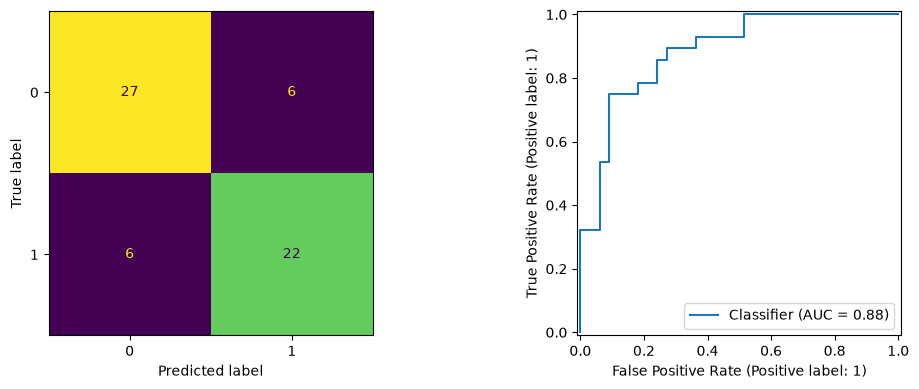

In [6]:
best_name = results.loc[0, "Model"]
best_pipe = searches[best_name].best_estimator_
y_pred = best_pipe.predict(X_test)
y_proba = best_pipe.predict_proba(X_test)[:, 1]

print("Selected model:", best_name)
print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Test ROC-AUC  :", round(roc_auc_score(y_test, y_proba), 4))
print()
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
plt.tight_layout(); plt.show()

## 6. Scores of all models on the test set
These numbers feed the **Models** page of the web app (`models/metrics.json`). The file
`models/reference.json` stores typical (training median / most common) values used by the
"Why this result?" explanation.

In [7]:
def thin(values, limit=60):
    step = max(1, len(values) // limit)
    keep = sorted(set(range(0, len(values), step)) | {len(values) - 1})
    return [round(float(values[i]), 4) for i in keep]

model_scores = []
for name, search in searches.items():
    pipe = search.best_estimator_
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    model_scores.append({
        "name": name,
        "cv_roc_auc": round(float(search.best_score_), 4),
        "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "accuracy": round(float(accuracy_score(y_test, pred)), 4),
        "precision": round(float(precision_score(y_test, pred)), 4),
        "recall": round(float(recall_score(y_test, pred)), 4),
        "f1": round(float(f1_score(y_test, pred)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, proba)), 4),
        "roc": {"fpr": thin(fpr), "tpr": thin(tpr)},
    })

metrics = {
    "selected": best_name,
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "models": model_scores,
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
}

categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
reference = {c: int(X_train[c].mode()[0]) if c in categorical else float(X_train[c].median())
             for c in FEATURES}

MODEL_DIR.mkdir(exist_ok=True)
(MODEL_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))
(MODEL_DIR / "reference.json").write_text(json.dumps(reference, indent=2))
pd.DataFrame(model_scores).drop(columns=["roc", "best_params"])

,name,cv_roc_auc,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.9074,0.7869,0.7778,0.7500,0.7636,0.8874
1,SVM,0.9074,0.8033,0.8077,0.7500,0.7778,0.8918
2,KNN,0.8902,0.8197,0.8696,0.7143,0.7843,0.9004
3,Random Forest,0.9127,0.8033,0.7857,0.7857,0.7857,0.8842


## 7. Save the model and scaler
The fitted scaler and model are pulled out of the best pipeline and saved separately,
exactly what `app.py` expects.

In [8]:
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(best_pipe.named_steps["model"], MODEL_DIR / "heart_disease_model.pkl")
joblib.dump(best_pipe.named_steps["scaler"], MODEL_DIR / "scaler.pkl")
print("Saved to", MODEL_DIR)

Saved to /home/teddy/Minor-Project/models


## 8. Sanity check: reload and predict one sample

In [9]:
model = joblib.load(MODEL_DIR / "heart_disease_model.pkl")
scaler = joblib.load(MODEL_DIR / "scaler.pkl")
sample = X_test.iloc[[0]]
print("Actual:", int(y_test.iloc[0]),
      "| Predicted:", int(model.predict(scaler.transform(sample))[0]),
      "| Probability:", round(float(model.predict_proba(scaler.transform(sample))[0][1]), 3))

Actual: 0 | Predicted: 0 | Probability: 0.198
